# Student t 1 dim

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm, t,multivariate_normal
from statsmodels.graphics.tsaplots import plot_acf

In [6]:
def independent_metropolis(n, target_density, proposal_density, proposal_sampler, burnin=100):
    total_n = n + burnin
    Y_proposals = proposal_sampler(size=total_n)
    pi_y = target_density(Y_proposals)
    q_y = proposal_density(Y_proposals)

    x = proposal_sampler(1)
    pi_x = target_density(x)
    q_x = proposal_density(x)

    X_samples = [x]
    alphas = []
    for i in range(total_n):
        y = Y_proposals[i]
        alpha = min(1, (pi_y[i] * q_x) / (pi_x * q_y[i]))
        if np.random.rand() < alpha:
            x = y
            pi_x = pi_y[i]
            q_x = q_y[i]
        X_samples.append(x)
        alphas.append(alpha)

    return np.array(X_samples[-n-1:-1]), Y_proposals[-n:], np.array(alphas[-n:])

# -------------------------------
# IMCV Estimator
# -------------------------------
def imcv_estimator(F, Fapprox, X, Y, alpha, eq_f):
    l = len(X)
    fX = F(X)
    fY = F(Y)
    fapp = Fapprox(Y)

    b_2 = np.cov(alpha * (fY - fX), (fapp - eq_f))[0,1] / np.var((fapp - eq_f))
    pg = fX + alpha * (fY - fX) - b_2 * (fapp - eq_f)
    numerator = np.mean(fX * (fX + pg)) - np.mean(fX) * np.mean(fX + pg)
    denominator = np.sum((fX[0 : l - 1] - pg[1 : l]) ** 2) / l
    b_1 = numerator / denominator

    delta = b_1* (alpha * (fY - fX) - b_2*(fapp - eq_f))
    # delta = alpha * (fY - fX) - (fapp - eq_f)
    return np.mean(fX + delta)

# -------------------------------
# Bias-Corrected SNIS Estimator
# -------------------------------
def snis_estimator(F, Fapp, samples, target_density, proposal_density, eq_f):
    w = target_density(samples) / proposal_density(samples)
    Z_hat = np.mean(w)
    corrections = (w / Z_hat)
    f_vals = F(samples)
    fapp = Fapp(samples)
    b_2 = np.cov(f_vals * corrections, (fapp - eq_f))[0,1] / np.var((fapp - eq_f))
    return np.mean(f_vals * corrections - b_2*(fapp-eq_f))
    # return np.mean(f_vals * corrections - (fapp-eq_f))

def cmc_estimator(F, target_sampler, n):
    samples = target_sampler(size=n)
    return np.mean(F(samples))
# -------------------------------
# Estimation and Comparison
# -------------------------------
def estimate(
    n, m, mean_true, F, Fapp, eq_f,
    target_density, proposal_density, proposal_sampler,
    DO_PRINT=True
):
    imcv_estimates = []
    snis_estimates = []

    for _ in range(m):
        X, Y, alpha = independent_metropolis(
            n, target_density, proposal_density, proposal_sampler
        )
        # plt.figure(figsize=(8, 4))
        # plot_acf(X, lags=40)  # You can change `lags=40` to any number you want
        # plt.title("Autocorrelation Plot")
        # plt.xlabel("Lag")
        # plt.ylabel("Autocorrelation")
        # plt.tight_layout()
        # plt.show()
        imcv = imcv_estimator(F, Fapp, X, Y, alpha, eq_f)
        imcv_estimates.append(imcv)

        x_samples = proposal_sampler(size=n)
        snis = snis_estimator(F,Fapp, x_samples, target_density, proposal_density, eq_f)
        snis_estimates.append(snis)

    imcv_estimates = np.array(imcv_estimates)
    snis_estimates = np.array(snis_estimates)

    bias_imcv = np.mean(imcv_estimates - mean_true)
    bias_snis = np.mean(snis_estimates - mean_true)
    var_imcv = np.var(imcv_estimates, ddof=1)
    var_snis = np.var(snis_estimates, ddof=1)
    mse_imcv = bias_imcv**2 + var_imcv
    mse_snis = bias_snis**2 + var_snis
    reduction_imcv = mse_snis / mse_imcv

    if DO_PRINT:
        print(f"Bias IMCV = {bias_imcv:.6f}")
        print(f"Bias SNIS = {bias_snis:.6f}")
        print(f"Var  IMCV = {var_imcv:.6e}")
        print(f"Var  SNIS = {var_snis:.6e}")
        print(f"Std  IMCV = {np.sqrt(var_imcv):.6e}")
        print(f"Std  SNIS = {np.sqrt(var_snis):.6e}")
        print(f"MSE  IMCV = {mse_imcv:.6e}")
        print(f"MSE  SNIS = {mse_snis:.6e}")
        print(f"Red.      = {reduction_imcv:.4f}")
        print()
    return imcv_estimates - mean_true, snis_estimates - mean_true
    # return bias_imcv,bias_snis


In [49]:
DOF = [16]
mean = 0
std = 1
N = 5000
M = 100
# Run it for different DOFs
F = lambda x: x
Fapp = lambda x: x
# from scipy.integrate import quad
# def integrand(x, df):
#     return np.exp(x) * t.pdf(x, df)

for dof in DOF:
    # eq_f = 1 - t.cdf(3, df=dof)
    # mean_true = norm.sf(3, loc=mean, scale=std)
    # Target: standard normal
    target_density = lambda x: norm.pdf(x, mean, std)

    # Proposal: t-distribution with df=dof
    proposal_density = lambda x: t.pdf(x, df=dof)
    proposal_sampler = lambda size=None: t.rvs(df=dof, size=size)

    # target_density = lambda x: t.pdf(x, df=dof)
    # target_sampler = lambda size=None: t.rvs(df=dof, size=size)
    # proposal_density = lambda x: norm.pdf(x, loc=mean, scale=std)
    # proposal_sampler = lambda size=None: norm.rvs(loc=mean, scale=std, size=size)

    # eq_f = E_q[F(x)] = P_q(x > 3)
    eq_f = 0

    # result, error = quad(integrand, 2, np.inf, args=(dof,))
    # mean_true = E_pi[F(x)] = P_pi(x > 3)
    mean_true = 0
    bias_imcv_list,bias_snis_list=estimate(
    n=N, m=M,
    mean_true=mean_true, F=F, Fapp = Fapp, eq_f=eq_f,
    target_density=target_density,
    proposal_density=proposal_density,
    proposal_sampler=proposal_sampler
    )

Bias IMCV = 0.000010
Bias SNIS = 0.000230
Var  IMCV = 9.983073e-06
Var  SNIS = 1.486163e-05
Std  IMCV = 3.159600e-03
Std  SNIS = 3.855079e-03
MSE  IMCV = 9.983179e-06
MSE  SNIS = 1.491449e-05
Red.      = 1.4940



0.04025811897863128
0.02169169376764678
Bias IMCV = -0.001497
Bias SNIS = -0.001292
Var  IMCV = 5.937698e-05
Var  SNIS = 5.328507e-05
MSE  IMCV = 6.161835e-05
MSE  SNIS = 5.495542e-05
Red.      = 0.8919



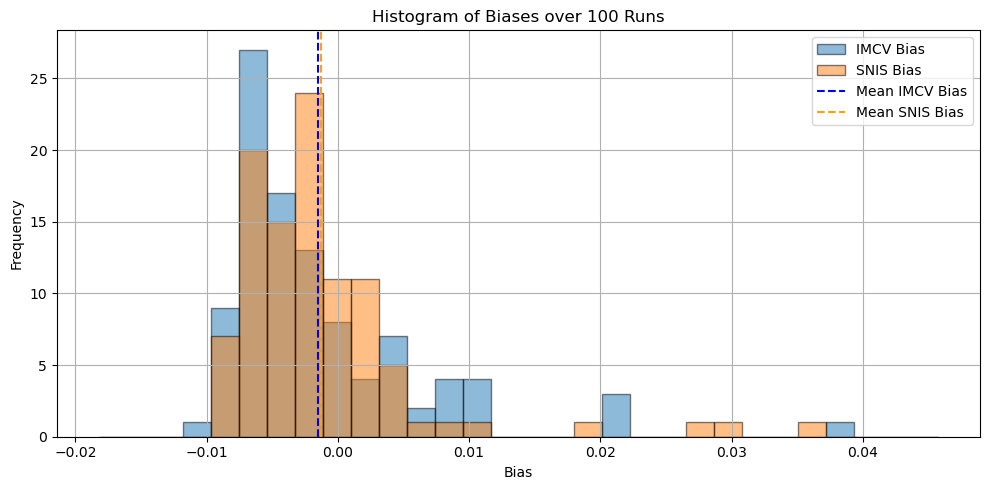

In [951]:
DOF = [8,16,32,64]
mean = 0
std = 1
N=100
M = 100
# Run it for different DOFs
F = lambda x: x
Fapp = lambda x: x
# from scipy.integrate import quad
# def integrand(x, df):
#     return np.exp(x) * t.pdf(x, df)

for dof in DOF:
    # eq_f = 1 - t.cdf(3, df=dof)
    # mean_true = norm.sf(3, loc=mean, scale=std)
    # Target: standard normal
    target_density = lambda x: norm.pdf(x, mean, std)

    # Proposal: t-distribution with df=dof
    proposal_density = lambda x: t.pdf(x, df=dof)
    proposal_sampler = lambda size=None: t.rvs(df=dof, size=size)

    # target_density = lambda x: t.pdf(x, df=dof)
    # target_sampler = lambda size=None: t.rvs(df=dof, size=size)
    # proposal_density = lambda x: norm.pdf(x, loc=mean, scale=std)
    # proposal_sampler = lambda size=None: norm.rvs(loc=mean, scale=std, size=size)

    # eq_f = E_q[F(x)] = P_q(x > 3)
    eq_f = 0

    # result, error = quad(integrand, 2, np.inf, args=(dof,))
    # mean_true = E_pi[F(x)] = P_pi(x > 3)
    mean_true = 0
    bias_imcv_list,bias_snis_list=estimate(
    n=N, m=M,
    mean_true=mean_true, F=F, Fapp = Fapp, eq_f=eq_f,
    target_density=target_density,
    proposal_density=proposal_density,
    proposal_sampler=proposal_sampler
    )
plt.figure(figsize=(10, 5))

# Histogram for IMCV
all_biases = np.array(bias_imcv_list + bias_snis_list)
min_bias = np.min(all_biases)
max_bias = np.max(all_biases)

# Create common bin edges (e.g., 20 bins between min and max)
bin_edges = np.linspace(min_bias, max_bias, 31)
plt.hist(bias_imcv_list, bins=bin_edges, alpha=0.5, label='IMCV Bias', color='tab:blue', edgecolor='black')
# Histogram for SNIS
plt.hist(bias_snis_list, bins=bin_edges, alpha=0.5, label='SNIS Bias', color='tab:orange', edgecolor='black')
plt.axvline(np.mean(bias_imcv_list), color='blue', linestyle='dashed', linewidth=1.5, label='Mean IMCV Bias')
plt.axvline(np.mean(bias_snis_list), color='orange', linestyle='dashed', linewidth=1.5, label='Mean SNIS Bias')

plt.xlabel('Bias')
plt.ylabel('Frequency')
plt.title('Histogram of Biases over 100 Runs')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Bias IMCV = 0.000757
Bias SNIS = 0.000932
Var  IMCV = 2.318187e-03
Var  SNIS = 1.515026e-03
Std  IMCV = 4.814755e-02
Std  SNIS = 3.892334e-02
MSE  IMCV = 2.318760e-03
MSE  SNIS = 1.515896e-03
Red.      = 0.6538



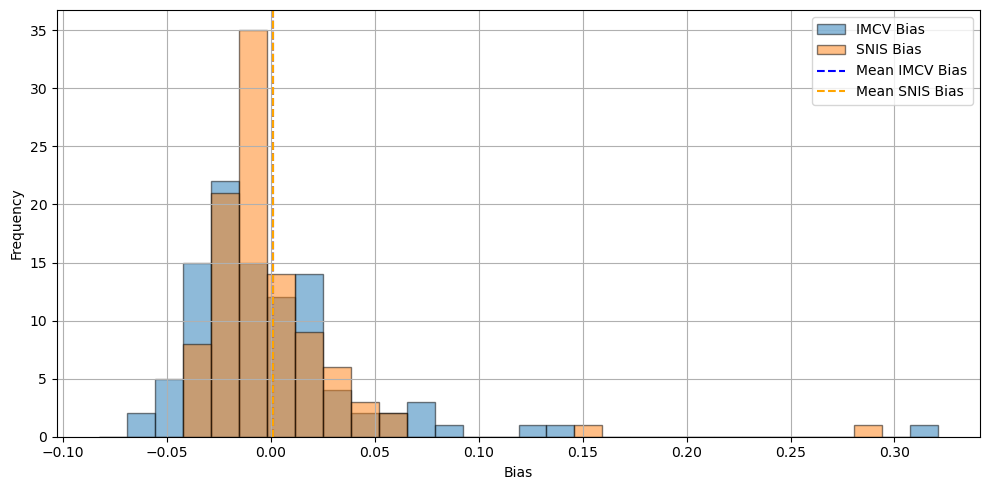

In [55]:
lam_target = 1
lam_proposal = 2

target_density = lambda x: lam_target * np.exp(-lam_target * x)
target_sampler = lambda size=None: np.random.exponential(scale=1 / lam_target, size=size)
proposal_density = lambda x: lam_proposal * np.exp(-lam_proposal * x)
proposal_sampler = lambda size=None: np.random.exponential(scale=1 / lam_proposal, size=size)

F = lambda x: (x > 2).astype(float)
Fapp = lambda x: (x > 2).astype(float)

# True target expectation and proposal expectation
mean_true = np.exp(-2 * lam_target)
eq_f = np.exp(-2 * lam_proposal)

N = 1000
M = 100

bias_imcv_list, bias_snis_list = estimate(
    n=N, m=M,
    mean_true=mean_true, F=F, Fapp=Fapp, eq_f=eq_f,
    target_density=target_density,
    proposal_density=proposal_density,
    proposal_sampler=proposal_sampler
)

# Plot ------------------------------------------------------------
plt.figure(figsize=(10, 5))

all_biases = np.array(bias_imcv_list + bias_snis_list)
min_bias = np.min(all_biases)
max_bias = np.max(all_biases)

bin_edges = np.linspace(min_bias, max_bias, 31)

plt.hist(bias_imcv_list, bins=bin_edges, alpha=0.5, label='IMCV Bias', color='tab:blue', edgecolor='black')
plt.hist(bias_snis_list, bins=bin_edges, alpha=0.5, label='SNIS Bias', color='tab:orange', edgecolor='black')

plt.axvline(np.mean(bias_imcv_list), color='blue', linestyle='dashed', linewidth=1.5, label='Mean IMCV Bias')
plt.axvline(np.mean(bias_snis_list), color='orange', linestyle='dashed', linewidth=1.5, label='Mean SNIS Bias')

plt.xlabel('Bias')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

[0.0002888645231332387, 1.984393512537097e-05, 8.244951740955519e-06, 0.00020380477758124237, 5.4832482468831765e-05, 3.3247109186269606e-05, 5.681396916769388e-05]
[0.00014836253869366433, 1.3086709180673006e-05, 4.2451860908473414e-05, 0.00013042770203058939, 5.04106127417775e-05, 7.007300066670219e-05, 4.781878108029436e-05]


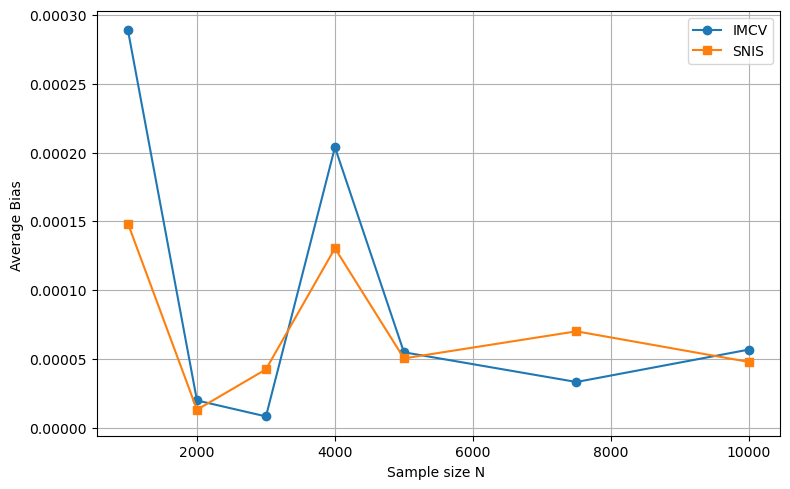

In [53]:
lam_target = 1
lam_proposal = 1.1

target_density = lambda x: lam_target * np.exp(-lam_target * x)
target_sampler = lambda size=None: np.random.exponential(scale=1 / lam_target, size=size)
proposal_density = lambda x: lam_proposal * np.exp(-lam_proposal * x)
proposal_sampler = lambda size=None: np.random.exponential(scale=1 / lam_proposal, size=size)

F = lambda x: (x > 1).astype(float)
Fapp = lambda x: (x > 1).astype(float)

# True target expectation and proposal expectation
mean_true = np.exp(-1 * lam_target)
eq_f = np.exp(-1 * lam_proposal)

# Estimator function placeholder (you must define this if not done yet)
# Should return (bias_imcv_list, bias_snis_list) of length M
# def estimate(n, m, mean_true, F, Fapp, eq_f, target_density, proposal_density, proposal_sampler):
#     ...

# Estimation parameters
M = 100
N_values = [1000,2000,3000,4000,5000,7500,10000]
# N_values = [5000]
avg_bias_imcv = []
avg_bias_snis = []

for N in N_values:
    bias_imcv_list, bias_snis_list = estimate(
        n=N, m=M,
        mean_true=mean_true, F=F, Fapp=Fapp, eq_f=eq_f,
        target_density=target_density,
        proposal_density=proposal_density,
        proposal_sampler=proposal_sampler,
        DO_PRINT=False
    )
    # avg_bias_imcv.append(np.mean(np.abs(bias_imcv_list)))
    # avg_bias_snis.append(np.mean(np.abs(bias_snis_list)))
    # avg_bias_imcv.append(np.mean(bias_imcv_list))
    # avg_bias_snis.append(np.mean(bias_snis_list))
    avg_bias_imcv.append(np.abs(np.mean(bias_imcv_list)))
    avg_bias_snis.append(np.abs(np.mean(bias_snis_list)))

print(avg_bias_imcv)
print(avg_bias_snis)
# Plotting
plt.figure(figsize=(8, 5))
plt.plot(N_values, avg_bias_imcv, marker='o', label='IMCV')
plt.plot(N_values, avg_bias_snis, marker='s', label='SNIS')
# plt.xscale('log')
# plt.yscale('log')
plt.xlabel('Sample size N ')
plt.ylabel('Average Bias ')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Bias IMCV = -0.000134
Bias SNIS = 0.000009
Var  IMCV = 1.115702e-06
Var  SNIS = 7.402212e-07
Std  IMCV = 1.056268e-03
Std  SNIS = 8.603611e-04
MSE  IMCV = 1.133788e-06
MSE  SNIS = 7.403000e-07
Red.      = 0.6529



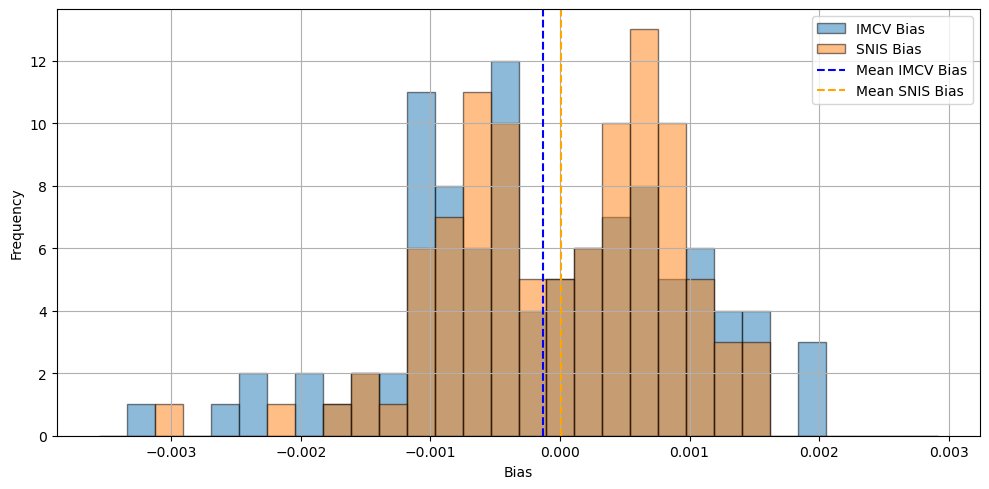

In [12]:
mu_target = 0.0
sigma_target = 1.0

mu_proposal = 0.1
sigma_proposal = 1.01

# Define densities and samplers
target_density = lambda x: norm.pdf(x, loc=mu_target, scale=sigma_target)
target_sampler = lambda size=None: np.random.normal(loc=mu_target, scale=sigma_target, size=size)
proposal_density = lambda x: norm.pdf(x, loc=mu_proposal, scale=sigma_proposal)
proposal_sampler = lambda size=None: np.random.normal(loc=mu_proposal, scale=sigma_proposal, size=size)

# Define F and Fapp
F = lambda x: np.exp(x) / (1 + np.exp(x))  # sigmoid
kappa = np.sqrt(np.pi / 8)
Fapp = lambda x: norm.cdf(kappa * x)
# Fapp = F

# Compute true expectation via MC
# mean_true = np.mean(F(target_sampler(size=10**8)))
mean_true = 0.5

# Compute analytical expectation of Fapp under proposal N(mu_q, sigma_q^2)
eq_f = norm.cdf((kappa * mu_proposal) / np.sqrt(1 + kappa**2 * sigma_proposal**2))
# eq_f = 0.5

# Estimation parameters
N = 1000
M = 100

bias_imcv_list, bias_snis_list = estimate(
    n=N, m=M,
    mean_true=mean_true, F=F, Fapp=Fapp, eq_f=eq_f,
    target_density=target_density,
    proposal_density=proposal_density,
    proposal_sampler=proposal_sampler
)

# Plot ------------------------------------------------------------
plt.figure(figsize=(10, 5))

all_biases = np.array(bias_imcv_list + bias_snis_list)
min_bias = np.min(all_biases)
max_bias = np.max(all_biases)
bin_edges = np.linspace(min_bias, max_bias, 31)

plt.hist(bias_imcv_list, bins=bin_edges, alpha=0.5, label='IMCV Bias', color='tab:blue', edgecolor='black')
plt.hist(bias_snis_list, bins=bin_edges, alpha=0.5, label='SNIS Bias', color='tab:orange', edgecolor='black')

plt.axvline(np.mean(bias_imcv_list), color='blue', linestyle='dashed', linewidth=1.5, label='Mean IMCV Bias')
plt.axvline(np.mean(bias_snis_list), color='orange', linestyle='dashed', linewidth=1.5, label='Mean SNIS Bias')

plt.xlabel('Bias')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

[0.0004600916734648941, -0.0009932395550648681, -5.121953261784107e-06, -0.000468006923878278, -0.0001643958783200611, -9.245031201076171e-05, 6.916160528400717e-05, 2.7448539633919132e-05, 9.757743319642742e-06, -5.397560347783492e-06]
[0.0039729267190292015, 0.000991913945761717, 0.00028646609186058325, -0.0004437280217606371, 0.0002247298127008751, 4.46343165314611e-05, -8.058448757359283e-05, 2.4351283941742573e-05, -1.1358594479836115e-05, -0.00010554447042935123]


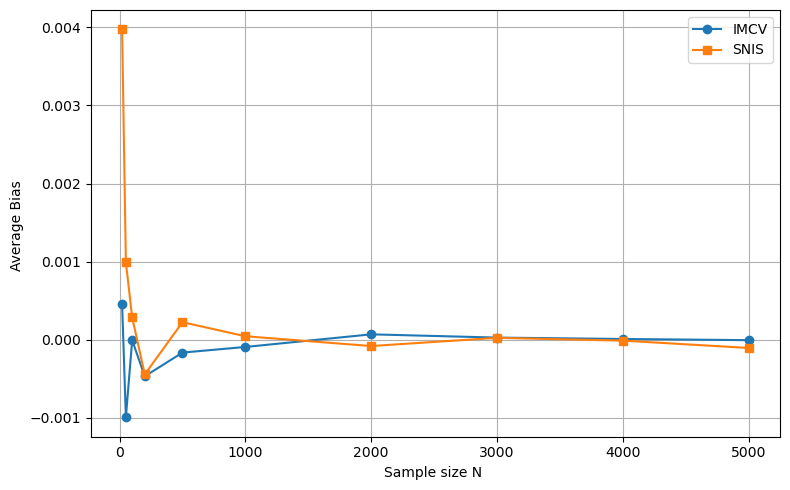

In [4]:


# Define parameters
mu_target = 0.0
sigma_target = 1.0

mu_proposal = 0.1
sigma_proposal = 1.01

# Define densities and samplers
target_density = lambda x: norm.pdf(x, loc=mu_target, scale=sigma_target)
target_sampler = lambda size=None: np.random.normal(loc=mu_target, scale=sigma_target, size=size)
proposal_density = lambda x: norm.pdf(x, loc=mu_proposal, scale=sigma_proposal)
proposal_sampler = lambda size=None: np.random.normal(loc=mu_proposal, scale=sigma_proposal, size=size)

# Define F and Fapp
F = lambda x: np.exp(x) / (1 + np.exp(x))  # sigmoid
kappa = np.sqrt(np.pi / 8)
Fapp = lambda x: norm.cdf(kappa * x)

# Assume this is the true value (or you can run a large MC to get it more accurately)
mean_true = 0.5
eq_f = norm.cdf((kappa * mu_proposal) / np.sqrt(1 + kappa ** 2 * sigma_proposal ** 2))

# Estimator function placeholder (you must define this if not done yet)
# Should return (bias_imcv_list, bias_snis_list) of length M
# def estimate(n, m, mean_true, F, Fapp, eq_f, target_density, proposal_density, proposal_sampler):
#     ...

# Estimation parameters
M = 100
N_values = [20,50,100,200,500,1000,2000,3000,4000,5000]
# N_values = [5000]
avg_bias_imcv = []
avg_bias_snis = []

for N in N_values:
    bias_imcv_list, bias_snis_list = estimate(
        n=N, m=M,
        mean_true=mean_true, F=F, Fapp=Fapp, eq_f=eq_f,
        target_density=target_density,
        proposal_density=proposal_density,
        proposal_sampler=proposal_sampler,
        DO_PRINT=False
    )
    # avg_bias_imcv.append(np.mean(np.abs(bias_imcv_list)))
    # avg_bias_snis.append(np.mean(np.abs(bias_snis_list)))
    avg_bias_imcv.append(np.mean(bias_imcv_list))
    avg_bias_snis.append(np.mean(bias_snis_list))
    # avg_bias_imcv.append(np.abs(np.mean(bias_imcv_list)))
    # avg_bias_snis.append(np.abs(np.mean(bias_snis_list)))

print(avg_bias_imcv)
print(avg_bias_snis)
# Plotting
plt.figure(figsize=(8, 5))
plt.plot(N_values, avg_bias_imcv, marker='o', label='IMCV')
plt.plot(N_values, avg_bias_snis, marker='s', label='SNIS')
# plt.xscale('log')
# plt.yscale('log')
plt.xlabel('Sample size N ')
plt.ylabel('Average Bias ')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Bias IMCV = -0.006816
Bias SNIS = 0.006551
Var  IMCV = 1.578682e-02
Var  SNIS = 2.005380e-02
Std  IMCV = 1.256456e-01
Std  SNIS = 1.416115e-01
MSE  IMCV = 1.583327e-02
MSE  SNIS = 2.009672e-02
Red.      = 1.2693



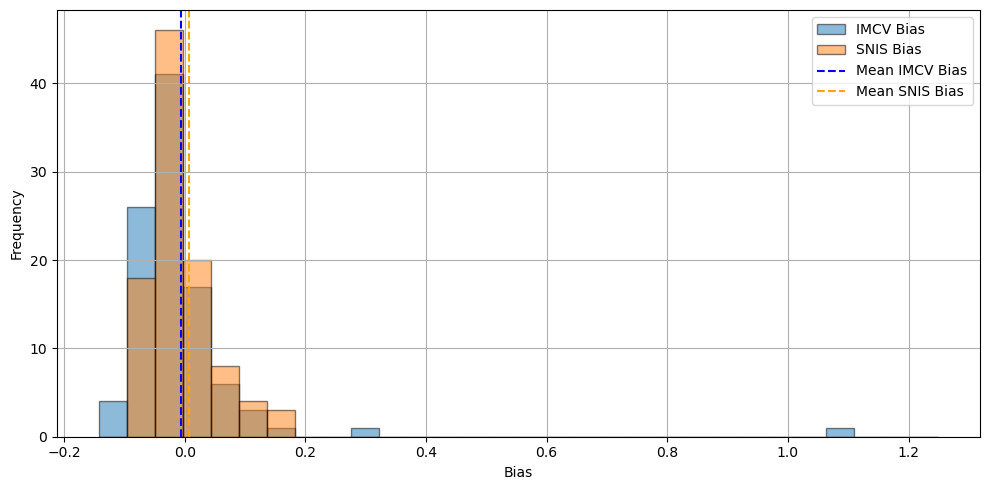

In [358]:
dim = 2
dof = 16
N = 10000
M = 100

# Target: 2D Student-t with dof
target_mean = np.zeros(dim)
target_cov = np.eye(dim)

# Proposal: 2D Gaussian
proposal_mean = np.array([-0.02, 0.01])
proposal_cov = np.array([[1,0.01],[0.01,1]])

from scipy.special import gamma

def student_t_density(x, df, loc, scale):
    d = x.shape[1]
    x_centered = x - loc
    inv_scale = np.linalg.inv(scale)
    maha = np.sum((x_centered @ inv_scale) * x_centered, axis=1)

    # Proper scalar normalization constant
    num = gamma((df + d) / 2)
    denom = (
        gamma(df / 2)
        * (df * np.pi) ** (d / 2)
        * np.linalg.det(scale) ** 0.5
    )
    Z = num / denom

    return Z * (1 + maha / df) ** (-(df + d) / 2)

# Define proposal functions
target_density = lambda x: student_t_density(x, df=dof, loc=target_mean, scale=target_cov)
target_sampler = lambda size=None: np.random.standard_t(df=dof, size=(size, dim))  # broadcasted
proposal_density = lambda x: multivariate_normal.pdf(x, mean=proposal_mean, cov=proposal_cov)
proposal_sampler = lambda size=None: np.random.multivariate_normal(mean=proposal_mean, cov=proposal_cov, size=size)

# Estimation target
# F = lambda x: x[:, 0] + x[:,1]
# Fapp = lambda x: x[:, 0] + x[:,1]
# mean_true = 0.0  # E[x1] under symmetric Student-t with mean zero
# eq_f = proposal_mean[0] + proposal_mean[1]
F = lambda x: (x[:, 0] + x[:,1])**2
Fapp = lambda x: (x[:, 0] + x[:,1])**2
mean_true = 2*dof/(dof-2)
eq_f = (proposal_mean[0] + proposal_mean[1])**2 + proposal_cov[0,0]+proposal_cov[1,1]+2*proposal_cov[0,1]
bias_imcv_list,bias_snis_list=estimate(
n=N, m=M,
mean_true=mean_true, F=F, Fapp = Fapp, eq_f=eq_f,
target_density=target_density,
proposal_density=proposal_density,
proposal_sampler=proposal_sampler
)
plt.figure(figsize=(10, 5))

# Histogram for IMCV
all_biases = np.array(bias_imcv_list + bias_snis_list)
min_bias = np.min(all_biases)
max_bias = np.max(all_biases)

# Create common bin edges (e.g., 20 bins between min and max)
bin_edges = np.linspace(min_bias, max_bias, 31) 
plt.hist(bias_imcv_list, bins=bin_edges, alpha=0.5, label='IMCV Bias', color='tab:blue', edgecolor='black')
# Histogram for SNIS
plt.hist(bias_snis_list, bins=bin_edges, alpha=0.5, label='SNIS Bias', color='tab:orange', edgecolor='black')
plt.axvline(np.mean(bias_imcv_list), color='blue', linestyle='dashed', linewidth=1.5, label='Mean IMCV Bias')
plt.axvline(np.mean(bias_snis_list), color='orange', linestyle='dashed', linewidth=1.5, label='Mean SNIS Bias')

plt.xlabel('Bias')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

[-0.07954279514849624, -0.029265833630136715, -0.02542620754059182, -0.022583692754271554, -0.0017732299593859668, -0.027403360790112706, -0.011086919017338302, -0.01523399964936127, -0.00401338350811343, 0.0016193611020659747, -0.015277829966900112]
[-0.01404801020291191, -0.03705657679962678, -0.014858821349343167, -0.016750376955345713, 0.05447623104439689, -0.020240866530150697, -0.01273150085870899, 0.002718299821723993, -0.019129094469430744, -0.008854903371371377, -0.014345743380467181]


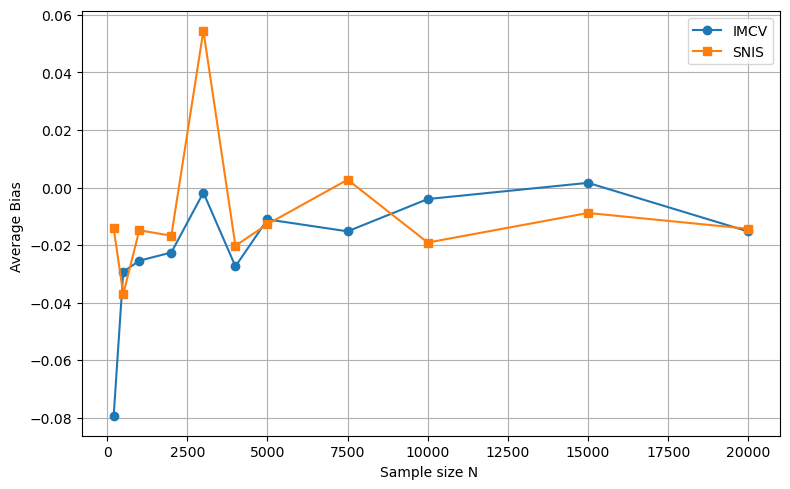

In [360]:
dim = 2
dof = 16

# Target: 2D Student-t with dof
target_mean = np.zeros(dim)
target_cov = np.eye(dim)
# Proposal: 2D Gaussian
proposal_mean = np.array([-0.02, 0.01])
proposal_cov = np.array([[1,0.01],[0.01,1]])

from scipy.special import gamma

def student_t_density(x, df, loc, scale):
    d = x.shape[1]
    x_centered = x - loc
    inv_scale = np.linalg.inv(scale)
    maha = np.sum((x_centered @ inv_scale) * x_centered, axis=1)

    # Proper scalar normalization constant
    num = gamma((df + d) / 2)
    denom = (
        gamma(df / 2)
        * (df * np.pi) ** (d / 2)
        * np.linalg.det(scale) ** 0.5
    )
    Z = num / denom

    return Z * (1 + maha / df) ** (-(df + d) / 2)

# Define proposal functions
target_density = lambda x: student_t_density(x, df=dof, loc=target_mean, scale=target_cov)
target_sampler = lambda size=None: np.random.standard_t(df=dof, size=(size, dim))  # broadcasted
# target_density = lambda x: multivariate_normal.pdf(x, mean=target_mean, cov=target_cov)
# target_sampler = lambda size=None: np.random.multivariate_normal(mean=target_mean, cov=target_cov, size=size)
proposal_density = lambda x: multivariate_normal.pdf(x, mean=proposal_mean, cov=proposal_cov)
proposal_sampler = lambda size=None: np.random.multivariate_normal(mean=proposal_mean, cov=proposal_cov, size=size)

# Estimation target
F = lambda x: (x[:, 0] + x[:,1])**2
Fapp = lambda x: (x[:, 0] + x[:,1])**2
mean_true = 2*dof/(dof-2)
eq_f = (proposal_mean[0] + proposal_mean[1])**2 + proposal_cov[0,0]+proposal_cov[1,1]+2*proposal_cov[0,1]
# F = lambda x: x[:, 0] + x[:,1]
# Fapp = lambda x: x[:, 0] + x[:,1]
# mean_true = 0
# eq_f = proposal_mean[0] + proposal_mean[1]
# Estimator function placeholder (you must define this if not done yet)
# Should return (bias_imcv_list, bias_snis_list) of length M
# def estimate(n, m, mean_true, F, Fapp, eq_f, target_density, proposal_density, proposal_sampler):
#     ...

# Estimation parameters
M = 100
N_values = [200,500,1000,2000,3000,4000,5000,7500,10000,15000,20000]
# N_values = [5000]
avg_bias_imcv = []
avg_bias_snis = []

for N in N_values:
    bias_imcv_list, bias_snis_list = estimate(
        n=N, m=M,
        mean_true=mean_true, F=F, Fapp=Fapp, eq_f=eq_f,
        target_density=target_density,
        proposal_density=proposal_density,
        proposal_sampler=proposal_sampler,
        DO_PRINT=False
    )
    # avg_bias_imcv.append(np.mean(np.abs(bias_imcv_list)))
    # avg_bias_snis.append(np.mean(np.abs(bias_snis_list)))
    avg_bias_imcv.append(np.mean(bias_imcv_list))
    avg_bias_snis.append(np.mean(bias_snis_list))
    # avg_bias_imcv.append(np.abs(np.mean(bias_imcv_list)))
    # avg_bias_snis.append(np.abs(np.mean(bias_snis_list)))

print(avg_bias_imcv)
print(avg_bias_snis)
# Plotting
plt.figure(figsize=(8, 5))
plt.plot(N_values, avg_bias_imcv, marker='o', label='IMCV')
plt.plot(N_values, avg_bias_snis, marker='s', label='SNIS')
# plt.xscale('log')
# plt.yscale('log')
plt.xlabel('Sample size N ')
plt.ylabel('Average Bias ')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Gradient descent

In [59]:
import jax
import jax.numpy as jnp
import optax
from jax.random import PRNGKey, normal
from scipy.stats import multivariate_normal
import scipy
import numpy as np

class OptimizerSettings:
    def __init__(
        self,
        dim: int = 16,
        learning_rate: float = 0.001,
        model=None,
        value: int = 10,
        decay_type: str = "none",  # 'none', 'exponential', 'linear'
        decay_steps: int = 10000,
        decay_rate: float = 0.9
    ):
        self.dim = dim
        self.lr_l = learning_rate
        self.lr_m = learning_rate * 10
        self.model = model
        self.value = value
        self.decay_type = decay_type
        self.decay_steps = decay_steps
        self.decay_rate = decay_rate

        self.target = self.model
        self.logtarget = jax.jit(self.target.logpdf)

    def set_distribution_parameters(self, t_mean, t_L, p_mean, p_L):
        self.t_mean = t_mean
        self.t_L = t_L
        self.p_mean = p_mean
        self.p_L = p_L

    def init_state(self):
        self.grad_val = 0
        self.grad_L = 0
        self.cum_obj = 0

    def objective_function(self, data):
        return self.logtarget(data, self.t_mean, self.t_L)

    def _make_schedule(self, init_value):
        if self.decay_type == "exponential":
            return optax.exponential_decay(
                init_value=init_value,
                transition_steps=self.decay_steps,
                decay_rate=self.decay_rate,
                staircase=True
            )
        elif self.decay_type == "linear":
            return optax.linear_schedule(
                init_value=init_value,
                end_value=0.0,
                transition_steps=self.decay_steps
            )
        else:  # no decay
            return optax.constant_schedule(init_value)

    def optimization_init(self):
        schedule_m = self._make_schedule(self.lr_m)
        schedule_l = self._make_schedule(self.lr_l)
        self.optimizer_mean = optax.adam(schedule_m)
        self.optimizer_L = optax.adam(schedule_l)
        self.opt_state_mean = self.optimizer_mean.init(self.p_mean)
        self.opt_state_L = self.optimizer_L.init(self.p_L)
        self.obj_grad = jax.grad(self.objective_function)

    def optimization_collect(self, sample, epsilon, batch_size):
        cur_grad = self.obj_grad(sample)
        self.grad_val += cur_grad / batch_size
        self.grad_L += (
            cur_grad.reshape((self.dim, 1)) @ epsilon.reshape((1, self.dim)) +
            jnp.diag(1 / jnp.diag(self.p_L))
        ) / batch_size
        self.cum_obj += (
            self.objective_function(sample) + jnp.sum(jnp.log(jnp.diag(self.p_L)))
        ) / batch_size

    def optimization_update(self):
        updates, self.opt_state_mean = self.optimizer_mean.update(-self.grad_val, self.opt_state_mean)
        self.p_mean = optax.apply_updates(self.p_mean, updates)

        updates, self.opt_state_L = self.optimizer_L.update(-self.grad_L, self.opt_state_L)
        self.p_L = optax.apply_updates(self.p_L, updates)

        self.p_L = jnp.tril(self.p_L)
        bounded_diag = jnp.clip(jnp.diag(self.p_L), a_min=0.001, a_max=1000.0)
        self.p_L = self.p_L - jnp.diag(jnp.diag(self.p_L)) + jnp.diag(bounded_diag)

# Define target log-pdf: standard normal
class StandardGaussian:
    def __init__(self, dim):
        self.dim = dim

    def logpdf(self, x, mean, L):
        # L is Cholesky of covariance matrix (i.e., lower triangular)
        solve = jax.scipy.linalg.solve_triangular(L, (x - mean), lower=True)
        return -0.5 * jnp.sum(solve**2) - jnp.sum(jnp.log(jnp.diag(L))) - 0.5 * self.dim * jnp.log(2 * jnp.pi)

class GP_Regression():

    def load_data(self, dataset):
        file  = "/home/ranbot/VRforIM/data/" + dataset + ".mat"
        mat = scipy.io.loadmat(file)
        if dataset == 'pendulum':
            self.Xtrain = mat['X_tr']
            self.Ytrain = mat['T_tr']
            self.Xtest = mat['X_tst']
            self.Ytest = mat['T_tst']
        elif dataset == 'boston':
            self.Xtrain = mat['X']
            self.Ytrain = mat['y']
            self.Xtest = mat['Xstar']
            self.Ytest = mat['ystar']
        elif dataset == 'bodyfat':
            self.Xtrain = mat['Xtrain'].toarray()
            self.Ytrain = mat['Ytrain']
            self.Xtest = mat['Xtest'].toarray()
            self.Ytest = mat['Ytest']
        mean_inputs = np.mean(np.array(self.Xtrain), axis=0)
        std_inputs = np.std(np.array(self.Xtrain), axis=0)
        self.Xtrain = (self.Xtrain- mean_inputs[None, :]) / std_inputs[None, :]
        self.Ytrain = self.Ytrain - np.mean(self.Ytrain)
        self.dim = 3
        self.n_data = self.Xtrain.shape[0]
        
    def logpdf(self, x, *paras):
        Xcov = jnp.expand_dims(self.Xtrain, axis=0).repeat(self.n_data, axis=0)
        Xcov2 = jnp.expand_dims(self.Xtrain, axis=0).repeat(self.n_data, axis=0).transpose(1,0,2)
        self.cov = jnp.exp( - jnp.sum((Xcov - Xcov2) ** 2 / jnp.exp(x[0]), axis = 2) / 2 ) * (jnp.exp(x[1]) ) + jnp.exp(x[2]) * jnp.diag(jnp.ones(self.n_data))
        # self.cov = jnp.exp( - jnp.sum((Xcov - Xcov2) ** 2 / jnp.exp(x[:-2]), axis = 2) / 2 ) * (jnp.exp(x[-2]) ) + jnp.exp(x[-1]) * jnp.diag(jnp.ones(self.n_data)) #different lengthscale
        self.L = jnp.linalg.cholesky(self.cov)
        v = jax.lax.linalg.triangular_solve(self.L, self.Ytrain, left_side=True, lower=True)
        log_lik = - 0.5 * jnp.sum(v * v) - 0.5 * self.n_data * jnp.log(2 * jnp.pi) - jnp.sum(jnp.log(jnp.diag(self.L)))
        log_prior = -(0.5 * x.shape[0]) * jnp.log(2. * jnp.pi) - (0.5 / 10) * jnp.sum(x * x)
        return log_lik + log_prior

In [237]:
from jax.random import PRNGKey, normal

# Instantiate target
dim = 100
target_model = StandardGaussian(dim)

# Initialize optimizer with decay settings (e.g., exponential decay)
opt = OptimizerSettings(
    dim=dim,
    learning_rate=0.01,
    model=target_model,
    decay_type="linear",  # or 'linear' or 'none'
    decay_steps=1000,
    decay_rate=0.8
)

# Set target and initial proposal parameters
t_mean = jnp.zeros(dim)
t_L = jnp.eye(dim)
p_mean = jnp.ones(dim) * 5.0
p_L = jnp.tril(jnp.ones((dim, dim)))  # upper triangle would be jnp.triu

opt.set_distribution_parameters(t_mean, t_L, p_mean, p_L)
opt.optimization_init()

key = PRNGKey(0)
batch_size = 50
num_steps = 1000

for step in range(num_steps):
    opt.init_state()
    for _ in range(batch_size):
        key, subkey = jax.random.split(key)
        epsilon = normal(subkey, shape=(dim,))
        sample = opt.p_mean + opt.p_L @ epsilon
        opt.optimization_collect(sample, epsilon, batch_size)
    opt.optimization_update()

    if step % 50 == 0 or step == num_steps - 1:
        mean_error = jnp.linalg.norm(opt.p_mean - t_mean)
        cov_error = jnp.linalg.norm(opt.p_L @ opt.p_L.T - t_L @ t_L.T)
        print(f"Step {step:3d} | Mean error: {mean_error:.4f} | Cov error: {cov_error:.4f}")

NameError: name 'StandardGaussian' is not defined

# Gaussian

In [54]:
import numpy as np
from scipy.stats import multivariate_normal
from tqdm import trange

def independent_metropolis_from_learned(n, target_density, proposal_density, proposal_sampler):
    Y_proposals = proposal_sampler(n)
    pi_y = target_density(Y_proposals)
    q_y = proposal_density(Y_proposals)

    x = proposal_sampler(1)[0]
    pi_x = target_density(x)
    q_x = proposal_density(x)
    X_samples = [x]
    alphas = []

    for i in range(n):
        y = Y_proposals[i]
        alpha = min(1, (pi_y[i] * q_x) / (pi_x * q_y[i]))
        if np.random.rand() < alpha:
            x = y
            pi_x = pi_y[i]
            q_x = q_y[i]
        X_samples.append(x)
        alphas.append(alpha)

    return np.array(X_samples[:-1]), Y_proposals, np.array(alphas)

def estimate_IMCV_with_learned_proposal(n, m, target_mean, target_cov, p_mean, p_L):
    d = len(p_mean)
    target_density = lambda x: multivariate_normal.pdf(x, mean=target_mean, cov=target_cov)
    proposal_density = lambda x: multivariate_normal.pdf(x, mean=p_mean, cov=p_L @ p_L.T)
    proposal_sampler = lambda size: np.random.multivariate_normal(mean=p_mean, cov=p_L @ p_L.T, size=size)

    F = lambda x: x[:, 0] if x.ndim == 2 else x[0]
    eq_f = p_mean[0]

    imcv_estimates = []
    for _ in trange(m, desc="IMCV"):
        X, Y, alpha = independent_metropolis_from_learned(n, target_density, proposal_density, proposal_sampler)
        fX = np.array([F(xi) for xi in X])
        fY = np.array([F(yi) for yi in Y])

        delta = alpha * (fY - fX) - (fY - eq_f)
        imcv = np.mean(fX + delta)
        imcv_estimates.append(imcv)

    imcv_estimates = np.array(imcv_estimates)
    mse = np.mean((imcv_estimates - 0.0) ** 2)
    var_est = np.var(imcv_estimates, ddof=1)

    reduction_mse = (1 / n) / mse
    reduction_var = (1 / n) / var_est

    return {
        "mse": mse,
        "var": var_est,
        "mse_reduction_ratio": reduction_mse,
        "var_reduction_ratio": reduction_var,
        "estimates": imcv_estimates
    }

n = 10000
m = 100

results = estimate_IMCV_with_learned_proposal(
    n=n,
    m=m,
    target_mean=opt.t_mean,
    target_cov=opt.t_L @ opt.t_L,
    p_mean=np.array(opt.p_mean),
    p_L=np.array(opt.p_L)
)

print("IMCV estimator results:")
print(f"  MSE: {results['mse']:.6e}")
print(f"  Variance: {results['var']:.6e}")
print(f"  MSE Reduction Ratio: {results['mse_reduction_ratio']:.4f}")
print(f"  Variance Reduction Ratio: {results['var_reduction_ratio']:.4f}")

IMCV:   0%|          | 0/100 [00:00<?, ?it/s]

IMCV: 100%|██████████| 100/100 [00:08<00:00, 12.01it/s]

IMCV estimator results:
  MSE: 6.746653e-05
  Variance: 6.813989e-05
  MSE Reduction Ratio: 1.4822
  Variance Reduction Ratio: 1.4676


In [55]:
import numpy as np
from scipy.stats import multivariate_normal

def bias_corrected_snis(F, samples, target_density, proposal_density, eq_f):
    w = target_density(samples) / proposal_density(samples)
    Z_hat = np.mean(w)
    corrections = ((w / Z_hat) - 1)
    f_vals = F(samples)
    return eq_f + np.mean((f_vals - eq_f) * corrections)

def run_bias_corrected_snis_gaussian(n, m, p_mean, p_L):
    dim = len(p_mean)
    target_mean = opt.t_mean
    target_cov = opt.t_L @ opt.t_L.T
    proposal_cov = p_L @ p_L.T

    target_density = lambda x: multivariate_normal.pdf(x, mean=target_mean, cov=target_cov)
    proposal_density = lambda x: multivariate_normal.pdf(x, mean=p_mean, cov=proposal_cov)
    proposal_sampler = lambda size: np.random.multivariate_normal(mean=p_mean, cov=proposal_cov, size=size)

    F = lambda x: x[:, 0]
    eq_f = p_mean[0]

    estimates = []
    for _ in range(m):
        x = proposal_sampler(size=n)
        est = bias_corrected_snis(F, x, target_density, proposal_density, eq_f)
        estimates.append(est)

    estimates = np.array(estimates)
    true_mean = 0.0
    mse = np.mean((estimates - true_mean) ** 2)
    var_est = np.var(estimates, ddof=1)

    reduction_mse = (1 / n) / mse
    reduction_var = (1 / n) / var_est

    return {
        "mse": mse,
        "var": var_est,
        "mse_reduction_ratio": reduction_mse,
        "var_reduction_ratio": reduction_var,
        "estimates": estimates
    }

results = run_bias_corrected_snis_gaussian(
    n=10000,
    m=100,
    p_mean=np.array(opt.p_mean),
    p_L=np.array(opt.p_L)
)

print(f"Bias-corrected SNIS:")
print(f"  MSE: {results['mse']:.6e}")
print(f"  Variance: {results['var']:.6e}")
print(f"  MSE Reduction Ratio: {results['mse_reduction_ratio']:.4f}")
print(f"  Variance Reduction Ratio: {results['var_reduction_ratio']:.4f}")


Bias-corrected SNIS:
  MSE: 2.435840e-05
  Variance: 2.449154e-05
  MSE Reduction Ratio: 4.1054
  Variance Reduction Ratio: 4.0830


# GP Regression

In [62]:
gp_model = GP_Regression()
gp_model.load_data('pendulum')
dim = gp_model.dim
opt = OptimizerSettings(
    dim=gp_model.dim,
    learning_rate=0.01,
    model=gp_model,
    decay_type='linear',
    decay_steps=1000,
    decay_rate=0.9
)

key = PRNGKey(0)
init_mean = jnp.zeros(opt.dim)
init_L = jnp.eye(opt.dim)

opt.set_distribution_parameters(init_mean, init_L, init_mean, init_L)
opt.init_state()
opt.optimization_init()

batch_size = 50
num_steps = 1000

for step in range(num_steps):
    opt.init_state()
    for _ in range(batch_size):
        key, subkey = jax.random.split(key)
        epsilon = normal(subkey, shape=(dim,))
        sample = opt.p_mean + opt.p_L @ epsilon
        opt.optimization_collect(sample, epsilon, batch_size)
    opt.optimization_update()

    if step % 50 == 0 or step == num_steps - 1:
        print(f"Step {step:3d}")

Step   0
Step  50
Step 100
Step 150
Step 200
Step 250
Step 300
Step 350
Step 400
Step 450
Step 500
Step 550
Step 600
Step 650
Step 700
Step 750
Step 800
Step 850
Step 900
Step 950
Step 999


In [78]:
N = 5000
M = 100
I = 1

In [79]:
def independent_metropolis_from_learned_gp(n, logtarget, proposal_density, proposal_sampler):
    Y_proposals = proposal_sampler(n)
    pi_y = np.exp(np.array([logtarget(y) for y in Y_proposals]))
    q_y = proposal_density(Y_proposals)

    x = proposal_sampler(1)[0]
    pi_x = np.exp(logtarget(x))
    q_x = proposal_density(x)
    X_samples = [x]
    alphas = []

    for i in range(n):
        y = Y_proposals[i]
        alpha = min(1, (pi_y[i] * q_x) / (pi_x * q_y[i]))
        if np.random.rand() < alpha:
            x = y
            pi_x = pi_y[i]
            q_x = q_y[i]
        X_samples.append(x)
        alphas.append(alpha)

    return np.array(X_samples[:-1]), Y_proposals, np.array(alphas)

def estimate_IMCV_with_learned_proposal_gp(n, m, model, p_mean, p_L):
    d = len(p_mean)
    
    # Proposal sampler and density
    proposal_cov = p_L @ p_L.T
    proposal_density = lambda x: multivariate_normal.pdf(x, mean=p_mean, cov=proposal_cov)
    proposal_sampler = lambda size: np.random.multivariate_normal(p_mean, proposal_cov, size)

    # Target log density from GP model
    logtarget = lambda x: float(model.logpdf(jnp.array(x)))

    F = lambda x: x[I]  # can be changed
    eq_f = p_mean[I]
    

    imcv_estimates = []
    for _ in trange(m, desc="IMCV"):
        X, Y, alpha = independent_metropolis_from_learned_gp(n, logtarget, proposal_density, proposal_sampler)
        fX = np.array([F(xi) for xi in X])
        fY = np.array([F(yi) for yi in Y])

        delta = alpha * (fY - fX) - (fY - eq_f)
        imcv = np.mean(fX + delta)
        imcv_estimates.append(imcv)

    imcv_estimates = np.array(imcv_estimates)
    var_est = np.var(imcv_estimates, ddof=1)
    true_mean = eq_f
    mse = np.mean((imcv_estimates - true_mean) ** 2)
    print(f"learned_mean {eq_f}")
    print(imcv_estimates)

    return {
        "var": var_est,
        "mse": mse,
        "estimates": imcv_estimates
    }

results = estimate_IMCV_with_learned_proposal_gp(
    n=N,
    m=M,
    model=gp_model,  # your GP_Regression instance
    p_mean=np.array(opt.p_mean),
    p_L=np.array(opt.p_L)
)

print("IMCV estimator results:")
print(f"  MSE: {results['mse']:.6e}")
print(f"  Variance: {results['var']:.6e}")

IMCV: 100%|██████████| 100/100 [15:04<00:00,  9.04s/it]

learned_mean 2.610140085220337
[2.61201526 2.60860664 2.60895773 2.60757053 2.61065101 2.60970462
 2.60796788 2.61192587 2.61013691 2.60854757 2.60877188 2.60778556
 2.61142453 2.61114355 2.60967703 2.60972271 2.60875298 2.61035055
 2.60998218 2.60771734 2.60752347 2.61115483 2.6119195  2.60797417
 2.61139326 2.60875893 2.60836596 2.60718013 2.61096078 2.6076058
 2.60723974 2.6102434  2.6103957  2.60628646 2.60977561 2.60888395
 2.61206581 2.60735825 2.61102384 2.61076847 2.61269803 2.61097871
 2.60934883 2.6107712  2.60755367 2.60943658 2.60930519 2.60857059
 2.60755995 2.61023062 2.61152631 2.61259294 2.61019019 2.60900887
 2.60754764 2.61136381 2.60934128 2.6144768  2.60875256 2.61147955
 2.60162707 2.61247408 2.60613611 2.60444826 2.60843156 2.61190694
 2.61353376 2.60805443 2.60857325 2.61154873 2.61001593 2.61071112
 2.60887579 2.61127632 2.61052129 2.60880215 2.61011218 2.60550681
 2.61058936 2.60856355 2.60891968 2.61007615 2.61037961 2.61553396
 2.60790388 2.61080219 2.6066245

In [80]:
def bias_corrected_snis_gp(F, samples, logtarget, proposal_density, eq_f):
    logw = np.array([logtarget(x) for x in samples])
    w = np.exp(logw)
    Z_hat = np.mean(w)
    corrections = ((w / Z_hat) - 1)
    f_vals = np.array([F(x) for x in samples])
    return eq_f + np.mean((f_vals - eq_f) * corrections)

def run_bias_corrected_snis_gp(n, m, model, p_mean, p_L):
    dim = len(p_mean)
    proposal_cov = p_L @ p_L.T

    # Define proposal
    proposal_density = lambda x: multivariate_normal.pdf(x, mean=p_mean, cov=proposal_cov)
    proposal_sampler = lambda size: np.random.multivariate_normal(p_mean, proposal_cov, size=size)

    # Define unnormalized log-target density
    logtarget = lambda x: float(model.logpdf(jnp.array(x)))

    F = lambda x: x[I]  # Feature function
    eq_f = p_mean[I]    # Expectation under proposal

    estimates = []
    for _ in trange(m, desc="SNIS"):
        x = proposal_sampler(n)
        est = bias_corrected_snis_gp(F, x, logtarget, proposal_density, eq_f)
        estimates.append(est)

    estimates = np.array(estimates)
    true_mean = eq_f
    mse = np.mean((estimates - true_mean) ** 2)
    var_est = np.var(estimates, ddof=1)
    print(f"learned_mean {eq_f}")
    print(estimates)

    return {
        "mse": mse,
        "var": var_est,
        "estimates": estimates
    }

results = run_bias_corrected_snis_gp(
    n=N,
    m=M,
    model=gp_model,  # Your GP_Regression instance
    p_mean=np.array(opt.p_mean),
    p_L=np.array(opt.p_L)
)

print(f"Bias-corrected SNIS:")
print(f"  MSE: {results['mse']:.6e}")
print(f"  Variance: {results['var']:.6e}")

SNIS: 100%|██████████| 100/100 [15:06<00:00,  9.06s/it]

learned_mean 2.610140085220337
[2.60906163 2.60839631 2.60890899 2.60907616 2.6079237  2.60734872
 2.60753832 2.6042609  2.60627049 2.60723286 2.60860428 2.608198
 2.60846964 2.60799168 2.60772196 2.60760084 2.6095876  2.607945
 2.60813308 2.60659334 2.60735858 2.61037665 2.60866599 2.6081332
 2.60732612 2.60487225 2.60788608 2.60974928 2.60885048 2.60813479
 2.60873486 2.6064428  2.60797625 2.60965064 2.60784479 2.60608489
 2.60681547 2.60519788 2.60792555 2.60635537 2.6064066  2.6066461
 2.60674471 2.60609502 2.60895879 2.60808115 2.60682233 2.60771507
 2.60902711 2.60717976 2.6101218  2.60769267 2.60384292 2.60525911
 2.60732474 2.60733406 2.60736872 2.60871735 2.60762117 2.60650669
 2.60759374 2.6065651  2.60948237 2.60882108 2.60603307 2.60825562
 2.60851537 2.60878559 2.60708361 2.60807022 2.60958191 2.60979448
 2.60762076 2.60710714 2.60526522 2.60603523 2.6082201  2.60882298
 2.60641394 2.60531388 2.60875222 2.60755023 2.60641307 2.60774219
 2.60830968 2.60650639 2.6091117  2.6

In [6]:
import numpy as np
from scipy.stats import norm

# Define parameters
mu = 1
sigma = 2
a = np.sqrt(np.pi / 8)

# Define function for Monte Carlo approximation
n_samples = 10**6
X_samples = np.random.normal(mu, sigma, size=n_samples)
lhs = np.mean(norm.cdf(a * X_samples))  # Monte Carlo estimate of E[Phi(aX)]

# Compute RHS: Phi(a * mu / sqrt(1 + a^2 * sigma^2))
rhs = norm.cdf(a * mu / np.sqrt(1 + a**2 * sigma**2))

lhs, rhs, np.abs(lhs - rhs)  # return both and their absolute error

(0.6521107714268938, 0.6520412832389009, 6.948818799290546e-05)